Dataset discovery
Searches the KaggleHub cache for WAV audio recordings and text annotation files.

In [8]:
from pathlib import Path

# KaggleHub's default Linux cache directory
cache_dir = Path.home() / ".cache" / "kagglehub"

# Find audio recordings and annotation files
wav_files = sorted(
    p for p in cache_dir.rglob("*")
    if p.is_file() and p.suffix.lower() == ".wav"
)

txt_files = sorted(
    p for p in cache_dir.rglob("*")
    if p.is_file() and p.suffix.lower() == ".txt"
)

print("Audio recordings found:", len(wav_files))
print("Text files found:", len(txt_files))

print("\nExample audio files:")
for file in wav_files[:10]:
    print(file)

print("\nExample text files:")
for file in txt_files[:10]:
    print(file)

Audio recordings found: 920
Text files found: 922

Example audio files:
/home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-sound-database/versions/1/ICBHI_final_database/101_1b1_Al_sc_Meditron.wav
/home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-sound-database/versions/1/ICBHI_final_database/101_1b1_Pr_sc_Meditron.wav
/home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-sound-database/versions/1/ICBHI_final_database/102_1b1_Ar_sc_Meditron.wav
/home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-sound-database/versions/1/ICBHI_final_database/103_2b2_Ar_mc_LittC2SE.wav
/home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-sound-database/versions/1/ICBHI_final_database/104_1b1_Al_sc_Litt3200.wav
/home/vinsam/.cache/kagglehub/datasets/nimalanparameshwaran/icbhi-2017-challenge-respiratory-

Annotation inspection
Confirms that an audio recording has a matching annotation file. Each row contains start time, end time, crackle label, and wheeze label.

In [9]:
if wav_files:
    recording = wav_files[0]
    annotation = recording.with_suffix(".txt")

    print("Recording:", recording.name)
    print("Matching annotation exists:", annotation.exists())

    if annotation.exists():
        print("\nAnnotation contents:")
        print(annotation.read_text()[:2000])
    else:
        print("No same-named annotation found.")
        print("We will inspect the dataset's folder structure next.")
else:
    print("No WAV files found. Check the dataset directory.")

Recording: 101_1b1_Al_sc_Meditron.wav
Matching annotation exists: True

Annotation contents:
0.036	0.579	0	0
0.579	2.45	0	0
2.45	3.893	0	0
3.893	5.793	0	0
5.793	7.521	0	0
7.521	9.279	0	0
9.279	11.15	0	0
11.15	13.036	0	0
13.036	14.721	0	0
14.721	16.707	0	0
16.707	18.507	0	0
18.507	19.964	0	0



Builds a pandas DataFrame called df, containing individual respiratory cycles, their labels, durations, patient IDs and audio paths.

In [10]:
import pandas as pd
from pathlib import Path

rows = []
missing_annotations = []

for wav_path in wav_files:
    txt_path = wav_path.with_suffix(".txt")

    if not txt_path.exists():
        missing_annotations.append(wav_path.name)
        continue

    try:
        annotations = pd.read_csv(
            txt_path,
            sep=r"\s+",
            header=None,
            names=["start", "end", "crackles", "wheezes"]
        )

        for _, ann in annotations.iterrows():
            rows.append({
                "recording": wav_path.name,
                "patient_id": wav_path.name.split("_")[0],
                "start": float(ann["start"]),
                "end": float(ann["end"]),
                "duration": float(ann["end"] - ann["start"]),
                "crackles": int(ann["crackles"]),
                "wheezes": int(ann["wheezes"]),
                "audio_path": str(wav_path)
            })

    except Exception as e:
        print(f"Could not parse {txt_path.name}: {e}")

df = pd.DataFrame(rows)

print("Total annotated respiratory cycles:", len(df))
print("Unique recordings:", df["recording"].nunique())
print("Unique patients:", df["patient_id"].nunique())
print("Missing annotation files:", len(missing_annotations))

print("\nWheeze labels:")
print(df["wheezes"].value_counts().sort_index())

print("\nCrackle labels:")
print(df["crackles"].value_counts().sort_index())

print("\nWheeze-positive recordings:",
      df.groupby("recording")["wheezes"].max().sum())

display(df.head())

Total annotated respiratory cycles: 6898
Unique recordings: 920
Unique patients: 126
Missing annotation files: 0

Wheeze labels:
wheezes
0    5506
1    1392
Name: count, dtype: int64

Crackle labels:
crackles
0    4528
1    2370
Name: count, dtype: int64

Wheeze-positive recordings: 336


,recording,patient_id,start,end,duration,crackles,wheezes,audio_path
0,101_1b1_Al_sc_Meditron.wav,101,0.036,0.579,0.543,0,0,/home/vinsam/.cache/kagglehub/datasets/nimalan...
1,101_1b1_Al_sc_Meditron.wav,101,0.579,2.450,1.871,0,0,/home/vinsam/.cache/kagglehub/datasets/nimalan...
2,101_1b1_Al_sc_Meditron.wav,101,2.450,3.893,1.443,0,0,/home/vinsam/.cache/kagglehub/datasets/nimalan...
3,101_1b1_Al_sc_Meditron.wav,101,3.893,5.793,1.900,0,0,/home/vinsam/.cache/kagglehub/datasets/nimalan...
4,101_1b1_Al_sc_Meditron.wav,101,5.793,7.521,1.728,0,0,/home/vinsam/.cache/kagglehub/datasets/nimalan...


Visualizes the number of wheeze-positive and wheeze-negative cycles. 

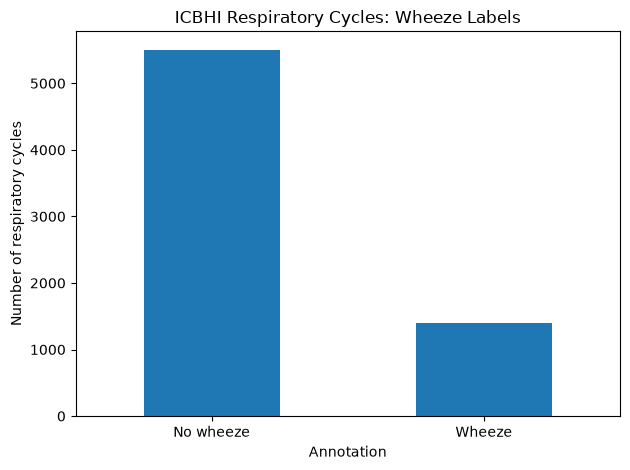

In [13]:
import matplotlib.pyplot as plt

label_counts = (
    df["wheezes"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

label_counts.index = ["No wheeze", "Wheeze"]

label_counts.plot(kind="bar")
plt.title("ICBHI Respiratory Cycles: Wheeze Labels")
plt.xlabel("Annotation")
plt.ylabel("Number of respiratory cycles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Filters the dataset to show respiratory cycles annotated as containing wheezes.

In [12]:
positive_cycles = df[df["wheezes"] == 1]

print("Wheeze-positive cycles:", len(positive_cycles))

display(
    positive_cycles[
        ["recording", "patient_id", "start", "end", "duration"]
    ].head(15)
)

Wheeze-positive cycles: 1392


,recording,patient_id,start,end,duration
36,103_2b2_Ar_mc_LittC2SE.wav,103,0.36400,3.25000,2.88600
38,103_2b2_Ar_mc_LittC2SE.wav,103,6.63600,11.17900,4.54300
39,103_2b2_Ar_mc_LittC2SE.wav,103,11.17900,14.25000,3.07100
40,103_2b2_Ar_mc_LittC2SE.wav,103,14.25000,16.99300,2.74300
48,104_1b1_Ar_sc_Litt3200.wav,104,0.00000,0.54469,0.54469
49,104_1b1_Ar_sc_Litt3200.wav,104,0.54469,2.96280,2.41811
50,104_1b1_Ar_sc_Litt3200.wav,104,2.96280,5.10850,2.14570
51,104_1b1_Ar_sc_Litt3200.wav,104,5.10850,7.21720,2.10870
52,104_1b1_Ar_sc_Litt3200.wav,104,7.21720,9.14420,1.92700
53,104_1b1_Ar_sc_Litt3200.wav,104,9.14420,10.67500,1.53080
